# 1. Inspect data & choose features

In [111]:
# importing necessary libraries

# ignore warnings
import warnings
warnings.filterwarnings("ignore")

# basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib
# sklearn libraries: model selection, preprocessing, pipeline, metrics, classifiers
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# set random state for reproducibility
RANDOM_STATE = 42
print("Setup complete")

Setup complete


In [112]:
# load dataframe
df = pd.read_csv('student_learning.csv')

In [113]:
# show the rows and columns of the dataframe
print("Rows, columns:", df.shape)

Rows, columns: (280, 7)


In [114]:
# display the first 5 rows of the dataframe
df.head(5)

,hours_studied,attendance,practice_tests,sleep_hours,study_method,final_score,passed
0,7.5,54,0,5.6,video,48,0
1,4.4,61,0,6.0,video,50,0
2,8.2,63,1,5.2,group,73,1
3,6.8,64,1,8.4,self,53,0
4,1.3,79,5,5.8,self,51,0


In [115]:
print("Data type:", df.dtypes)

Data type: hours_studied     float64
attendance          int64
practice_tests      int64
sleep_hours       float64
study_method          str
final_score         int64
passed              int64
dtype: object


In [116]:
print(f"Missing values in each columns:\n{df.isnull().sum()}")

Missing values in each columns:
hours_studied     0
attendance        0
practice_tests    0
sleep_hours       0
study_method      0
final_score       0
passed            0
dtype: int64


In [117]:
print(f"Duplicated rows: {df.duplicated().sum()}")

Duplicated rows: 0


In [118]:
print("Target balance (counts):"); print(df["passed"].value_counts())
print("\nTarget balance (share):"); print(df["passed"].value_counts(normalize=True).round(3))

Target balance (counts):
passed
0    157
1    123
Name: count, dtype: int64

Target balance (share):
passed
0    0.561
1    0.439
Name: proportion, dtype: float64


In [119]:
# display the summary statistics of the dataframe
df.describe().T

,count,mean,std,min,25%,50%,75%,max
hours_studied,280.0,4.882857,2.580154,0.6,2.575,4.8,7.20,9.4
attendance,280.0,76.085714,13.869843,52.0,63.750,76.5,89.00,100.0
practice_tests,280.0,3.167857,1.981194,0.0,2.000,3.0,5.00,6.0
sleep_hours,280.0,6.651429,1.336528,4.5,5.475,6.6,7.80,9.0
final_score,280.0,58.228571,15.613542,15.0,47.750,59.0,69.25,94.0
passed,280.0,0.439286,0.497189,0.0,0.000,0.0,1.00,1.0


In [120]:
print(df.groupby("passed")["final_score"].describe().round(2))

        count   mean    std   min   25%   50%   75%   max
passed                                                   
0       157.0  47.45  10.90  15.0  41.0  48.0  58.0  61.0
1       123.0  71.98   8.09  62.0  65.0  71.0  77.0  94.0


<Axes: title={'center': 'Target Balance'}, xlabel='passed'>

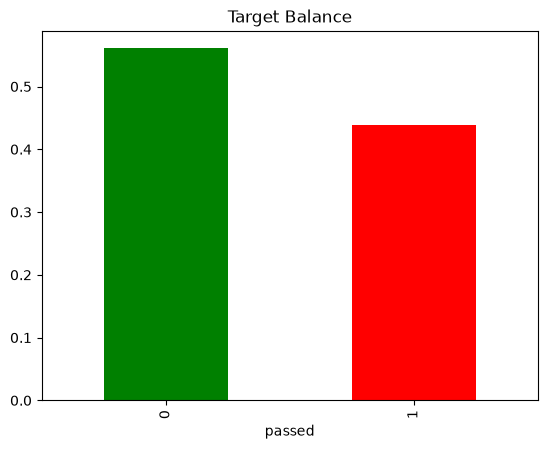

In [121]:
# check the dataframe is balanced or not
df["passed"].value_counts(normalize=True).plot(kind="bar", title="Target Balance", color=["green", "red"])

**Leakage decision.** `final_score` is only known *after* the exam, and it basically determines `passed`. Using it would give an unrealistically perfect model that is useless for predicting *before* the result. So:

- **y** = `passed`
- **X** = `hours_studied`, `attendance`, `practice_tests`, `sleep_hours` (numeric) and `study_method` (categorical)
- **Excluded:** `final_score` (leakage)

In [122]:
df.columns

Index(['hours_studied', 'attendance', 'practice_tests', 'sleep_hours',
       'study_method', 'final_score', 'passed'],
      dtype='str')

In [123]:
# separate features, target variables for better understanding of the data and for further processing
TARGET = "passed"
NUMERICAL = ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours']
CATEGORIAL = ["study_method"]
FEATURES = NUMERICAL + CATEGORIAL

# display the independent and dependent variables
X = df[FEATURES]
y = df[TARGET]
# 
assert "final_score" not in X.columns
print("Used Features:", FEATURES)
print("Target feature:", TARGET)

Used Features: ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours', 'study_method']
Target feature: passed


# 2. Split and baseline

In [124]:
# train and test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
# 
print(f"Train: {X_train.shape} | Test: {X_test.shape}.")

Train: (224, 5) | Test: (56, 5).


In [125]:
# Train DummyClassifier as a simple baseline.
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print(f"Dummy accuracy: {round(accuracy_score(y_test, dummy_pred), 3)}")
print(f"F1 score      : {f1_score(y_test, dummy_pred, zero_division=0)}")

Dummy accuracy: 0.554
F1 score      : 0.0


The Dummy model always predicts the majority class (fail). Any real model must beat this to be useful. Its F1 is 0 because it never predicts a pass.

# 3. Train at least two candidate models

In [126]:
# 1. Preprocessor configuration
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), NUMERICAL),
    ("cate", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                       ("oneHot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORIAL)
])

# 2. Corrected Model Pipelines (All steps wrapped properly in tuples)
log_reg = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

# Note: KMeans is left out of the supervised loop below because it's unsupervised clustering
km = Pipeline([
    ("prep", preprocessor),
    ("model", KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=5))
])

decisionTree = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE, criterion='gini'))
])

svc_clf = Pipeline([
    ("prep", preprocessor),
    ("model", SVC(kernel='rbf', C=1.0, gamma='scale', random_state=RANDOM_STATE))
])

rf = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=3, random_state=RANDOM_STATE))
])

# 3. Supervised evaluation loop (Including all valid classification pipelines)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models_to_evaluate = [
    ("LogisticRegression", log_reg),
    ("DecisionTree", decisionTree),
    ("SVC", svc_clf),
    ("RandomForest", rf)
]

# Assuming X_train and y_train are predefined arrays/DataFrames
for name, pipe in models_to_evaluate:
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    print(f"{name:20s} 5-fold CV F1 (train-only): {s.mean():.3f} ~approx {s.std():.3f}")

LogisticRegression   5-fold CV F1 (train-only): 0.797 ~approx 0.084
DecisionTree         5-fold CV F1 (train-only): 0.761 ~approx 0.075
SVC                  5-fold CV F1 (train-only): 0.779 ~approx 0.074
RandomForest         5-fold CV F1 (train-only): 0.776 ~approx 0.105


In [127]:
# fitted the candidate model
log_reg.fit(X_train, y_train)
rf.fit(X_train, y_train)
print("Both pipelines fitted on the training set.")

Both pipelines fitted on the training set.


WHY These models?
- `LogisticRegression`: Simple, fast, interpretable baseline for tabular data.
- `RandomForestClassifier`: Captures non-linear effects and interactions between features without much turning.
- Project's assigned on these models.

# 4. Evaluate fairly

In [128]:
# fair evaluation on candidate models with baseline model
models = {
    "Dummy (Baseline)": dummy,
    "LogisticRegression": log_reg,
    "RandomForest": rf
}

rows, preds = [], {}

for name, m in models.items():
    p = m.predict(X_test); preds[name] = p
    rows.append({"models": name, 
                 "accuracy": round((accuracy_score(y_test, p)), 3),
                 "f1":round(f1_score(y_test, p, zero_division=0), 3)})

result = pd.DataFrame(rows).set_index("models")
result

,accuracy,f1
models,,
Dummy (Baseline),0.554,0.00
LogisticRegression,0.750,0.72
RandomForest,0.786,0.75


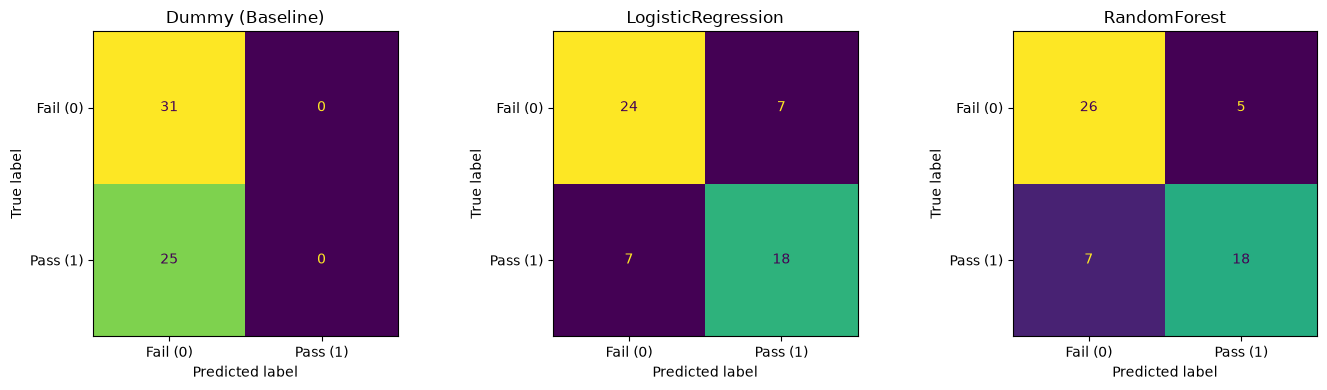

In [129]:
# confusion matrix chart
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["Fail (0)", "Pass (1)"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=120); plt.show()
plt.show()

In [130]:
# detailed model evaluation report
for name in ["LogisticRegression", "RandomForest"]:
    print(f"{"="*60}\n\t\t\t{name}\n{"="*60}")
    print(classification_report(y_test, preds[name], target_names=["Fail", "Pass"]))

			LogisticRegression
              precision    recall  f1-score   support

        Fail       0.77      0.77      0.77        31
        Pass       0.72      0.72      0.72        25

    accuracy                           0.75        56
   macro avg       0.75      0.75      0.75        56
weighted avg       0.75      0.75      0.75        56

			RandomForest
              precision    recall  f1-score   support

        Fail       0.79      0.84      0.81        31
        Pass       0.78      0.72      0.75        25

    accuracy                           0.79        56
   macro avg       0.79      0.78      0.78        56
weighted avg       0.79      0.79      0.78        56



# 5. Save and predict

In [131]:
# save the candidate models [LogisticRegression, RandomForest]
joblib.dump(log_reg, "Student-Log_R_model.joblib")

['Student-Log_R_model.joblib']

In [132]:
joblib.dump(rf, "Student-rf_model.joblib")

['Student-rf_model.joblib']

Logistic Regression

In [134]:
# Reload in a fresh object and predict WITHOUT retraining
loaded = joblib.load("Student-Log_R_model.joblib")
new_students = pd.read_csv("new_student_learning.csv")
print("Columns in new file:", list(new_students.columns))

pred = loaded.predict(new_students[FEATURES])
proba = loaded.predict_proba(new_students[FEATURES])[:, 1]
out = new_students.copy()
out["predicted_passed"] = pred
out["pass_probability"] = proba.round(3)
out.to_csv("new_student_predictions.csv", index=False)
print("Reloaded model matches original on test set:",
      bool((loaded.predict(X_test) == log_reg.predict(X_test)).all()))
out

Columns in new file: ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours', 'study_method', 'final_score', 'passed']
Reloaded model matches original on test set: True


,hours_studied,attendance,practice_tests,sleep_hours,study_method,final_score,passed,predicted_passed,pass_probability
0,7.5,54,0,5.6,video,48,0,0,0.271
1,4.4,61,0,6.0,video,50,0,0,0.061
2,8.2,63,1,5.2,group,73,1,1,0.684
3,6.8,64,1,8.4,self,53,0,0,0.282
4,1.3,79,5,5.8,self,51,0,0,0.108
...,...,...,...,...,...,...,...,...,...
275,4.0,63,4,7.2,video,42,0,0,0.170
276,3.4,66,4,6.6,group,49,0,0,0.207
277,5.0,76,4,6.3,video,54,0,0,0.465
278,8.4,80,0,6.9,group,82,1,1,0.779


RandomForest

In [136]:
# Reload in a fresh object and predict WITHOUT retraining
loaded = joblib.load("Student-rf_model.joblib")
new_students = pd.read_csv("new_student_learning.csv")
print("Columns in new file:", list(new_students.columns))

pred = loaded.predict(new_students[FEATURES])
proba = loaded.predict_proba(new_students[FEATURES])[:, 1]
out = new_students.copy()
out["predicted_passed"] = pred
out["pass_probability"] = proba.round(3)
out.to_csv("new_student_rf_predictions.csv", index=False)
print("Reloaded model matches original on test set:",
      bool((loaded.predict(X_test) == rf.predict(X_test)).all()))

Columns in new file: ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours', 'study_method', 'final_score', 'passed']
Reloaded model matches original on test set: True


---
testing code

In [ ]:
# save the complete fitted pipeline with joblib, reload it, predict new reocrds
cv_f1 = {n: cross_val_score(p, X_train, y_train, cv=cv, scoring="f1").mean()
         for n, p in [("LogisticRegression", log_reg), ("RandomForest", rf)]}
best_name = max(cv_f1, key=cv_f1.get)
best_model = {"LogisticRegression": log_reg, "RandomForest": rf}[name]
print(f"CV F1:{{k: round(v,3) for k, v in cv_f1.items()}}")
print("Selected final model:", best_name)
# joblib.dump(best_model)
print("Model Saved")

---

# 6. Simple Streamlit interface